# Part 1: Data Preparation and Exploratory Analysis

**Personal project: Decarbonizing Chicago's Large Buildings**

**Name:** Bernard Issifu

This notebook introduces the Chicago Energy Benchmarking dataset, cleans it, engineers the features used
in Parts 2 and 3, and explores how greenhouse gas (GHG) intensity varies across buildings and over time.
The same steps are implemented in R in `r/01_data_preparation_eda.Rmd`.

In [1]:
# ---- Setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
FIG_DIR = "../report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

---
# 1. The dataset

Chicago's Energy Benchmarking Ordinance requires buildings of 50,000 sq ft or more to report their
annual energy use to the city. The **Chicago Energy Benchmarking** dataset (City of Chicago Data Portal)
holds those reports for 2014–2023: one row per building per year, with the property type, floor area,
year built, number of buildings, community area and location; annual electricity, natural gas, district
steam, district chilled water and other fuel use; site and source energy use intensity (EUI, energy per
sq ft); the ENERGY STAR score; the Chicago Energy Rating (0–4 stars); and total and per-sq-ft greenhouse
gas emissions. Buildings are one of the largest sources of emissions in large US cities, so knowing
which buildings emit the most per sq ft, and why, points to where retrofits matter most.

In [2]:
raw = pd.read_csv("../data/chicago_energy_benchmarking.csv", low_memory=False)
print(raw.shape)
print(f"Distinct buildings: {raw['ID'].nunique():,}")
raw.head(3)

(28329, 30)
Distinct buildings: 3,852


,Data Year,ID,Property Name,Reporting Status,Address,ZIP Code,Chicago Energy Rating,Exempt From Chicago Energy Rating,Community Area,Primary Property Type,...,Site EUI (kBtu/sq ft),Source EUI (kBtu/sq ft),Weather Normalized Site EUI (kBtu/sq ft),Weather Normalized Source EUI (kBtu/sq ft),Total GHG Emissions (Metric Tons CO2e),GHG Intensity (kg CO2e/sq ft),Latitude,Longitude,Location,Row_ID
0,2021,101671,NaN,Not Submitted,6101 6115 N SEELEY AVE,60659,0.0,False,WEST RIDGE,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,41.990462,-87.706208,"(41.99046172, -87.70620782)",2021-101671
1,2021,101826,Drexel Building,Not Submitted,8136 8142 S DREXEL AVE,60619,0.0,False,CHATHAM,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,41.744013,-87.605499,"(41.74401302, -87.60549928)",2021-101826
2,2021,102323,NaN,Not Submitted,3515 3525 W FRANKLIN BLVD,60624,0.0,False,HUMBOLDT PARK,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,41.880824,-87.723279,"(41.8808242, -87.72327934)",2021-102323


In [3]:
# Reports per year and reporting status
display(raw["Data Year"].value_counts().sort_index().to_frame("rows").T)
raw["Reporting Status"].value_counts().to_frame("rows")

Data Year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
rows,243,1521,2717,2797,3430,3438,3582,3550,3613,3438


,rows
Reporting Status,
Submitted,17572
Submitted Data,5621
Not Submitted,3867
Exempt,957
Not Covered 2024,312


---
# 2. Data quality

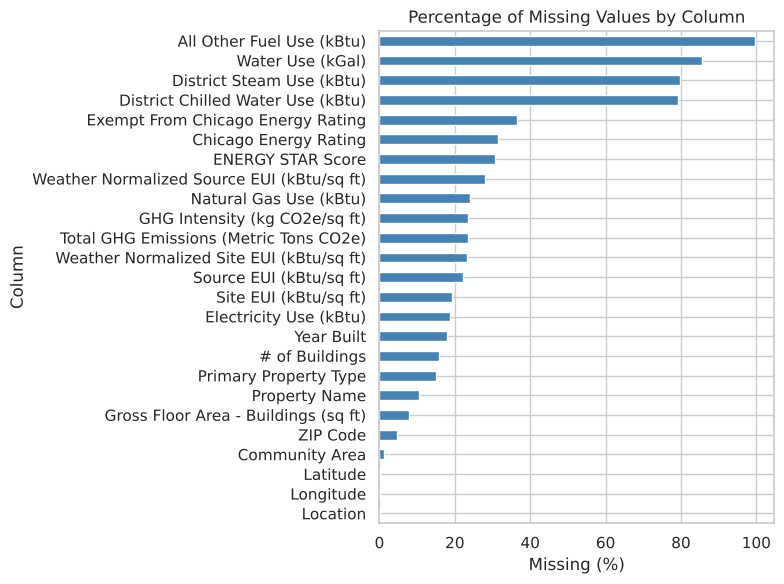

,pct_missing
All Other Fuel Use (kBtu),99.7
Water Use (kGal),85.7
District Steam Use (kBtu),79.7
District Chilled Water Use (kBtu),79.1
Exempt From Chicago Energy Rating,36.6
Chicago Energy Rating,31.5
ENERGY STAR Score,30.7
Weather Normalized Source EUI (kBtu/sq ft),28.0
Natural Gas Use (kBtu),24.0
GHG Intensity (kg CO2e/sq ft),23.4


In [4]:
missing = (raw.isna().mean() * 100).round(1)
missing = missing[missing > 0].sort_values(ascending=False).to_frame("pct_missing")

ax = missing["pct_missing"].plot(kind="barh", color="steelblue", figsize=(8, 6))
ax.invert_yaxis()
ax.set_title("Percentage of Missing Values by Column")
ax.set_xlabel("Missing (%)")
ax.set_ylabel("Column")
plt.tight_layout()
plt.show()
missing

**Interpretation.** Fuel-specific columns are mostly empty because few buildings use district steam (79.7% missing), chilled water (79.1%) or other fuels (99.7%); a missing fuel almost always means the building does not use it. The core outcome columns, GHG intensity and site EUI, are missing for 23.4% and 19.3% of rows, mainly reports marked 'Not Submitted' or 'Exempt', which contain only the building's address. ENERGY STAR scores are missing for 30.7% of rows, because the score does not exist for every property type.

---
# 3. Cleaning

Each step states what it does and why.

In [5]:
df = raw.rename(columns={
    "Data Year": "year", "Primary Property Type": "property_type",
    "Gross Floor Area - Buildings (sq ft)": "floor_area", "Year Built": "year_built",
    "# of Buildings": "n_buildings", "ENERGY STAR Score": "energy_star",
    "Electricity Use (kBtu)": "elec_kbtu", "Natural Gas Use (kBtu)": "gas_kbtu",
    "District Steam Use (kBtu)": "steam_kbtu", "District Chilled Water Use (kBtu)": "chilled_kbtu",
    "All Other Fuel Use (kBtu)": "other_kbtu", "Site EUI (kBtu/sq ft)": "site_eui",
    "GHG Intensity (kg CO2e/sq ft)": "ghg_intensity", "Total GHG Emissions (Metric Tons CO2e)": "ghg_total",
    "Community Area": "community_area", "Latitude": "lat", "Longitude": "lon"})
steps = [("Raw building-years", len(df))]

# (1) Keep reports that contain the outcome and the energy intensity
df = df.dropna(subset=["ghg_intensity", "site_eui"])
steps.append(("Has GHG intensity and site EUI", len(df)))

# (2) Remove physically implausible values (data-entry errors): site EUI outside 5-1,000 kBtu/sq ft
#     or GHG intensity outside 0.5-150 kg CO2e/sq ft (typical buildings use 50-150 kBtu/sq ft)
df = df[df["site_eui"].between(5, 1000) & df["ghg_intensity"].between(0.5, 150)]
steps.append(("Plausible EUI and GHG intensity", len(df)))

# (3) Building characteristics needed for the models
df = df.dropna(subset=["floor_area", "year_built", "lat", "lon"])
df = df[(df["floor_area"] > 0) & (df["year_built"].between(1850, 2023))]
steps.append(("Has floor area, year built and location", len(df)))

# (4) One report per building per year
df = df.sort_values(["ID", "year"]).drop_duplicates(["ID", "year"], keep="last")
steps.append(("One row per building-year", len(df)))

pd.DataFrame(steps, columns=["step", "rows"])

,step,rows
0,Raw building-years,28329
1,Has GHG intensity and site EUI,21708
2,Plausible EUI and GHG intensity,21634
3,"Has floor area, year built and location",21618
4,One row per building-year,21618


---
# 4. Feature engineering

In [6]:
# (a) 60+ property types grouped into 10 categories with similar energy use
group_map = {
    "Multifamily Housing": "Multifamily", "Residential": "Multifamily",
    "Residence Hall/Dormitory": "Multifamily",
    "K-12 School": "K-12 school",
    "Office": "Office", "Financial Office": "Office",
    "College/University": "Higher education", "Adult Education": "Higher education",
    "Hotel": "Hotel",
    "Retail Store": "Retail", "Strip Mall": "Retail", "Enclosed Mall": "Retail", "Other - Mall": "Retail",
    "Wholesale Club/Supercenter": "Retail", "Automobile Dealership": "Retail", "Commercial": "Retail",
    "Supermarket/Grocery Store": "Grocery",
    "Hospital (General Medical & Surgical)": "Healthcare", "Other - Specialty Hospital": "Healthcare",
    "Medical Office": "Healthcare",
    "Senior Care Community": "Senior living", "Senior Living Community": "Senior living",
    "Residential Care Facility": "Senior living",
}
df["property_group"] = df["property_type"].map(group_map).fillna("Other")

# (b) Size, age and number of buildings
df["log_floor_area"] = np.log10(df["floor_area"])
df["building_age"] = df["year"] - df["year_built"]
df["n_buildings"] = df["n_buildings"].fillna(1).clip(lower=1)

# (c) Distance to downtown (the Loop, 41.8781 N, 87.6298 W) in km, from latitude and longitude
km_per_deg_lat, km_per_deg_lon = 111.0, 111.0 * np.cos(np.radians(41.88))
df["dist_downtown_km"] = np.hypot((df["lat"] - 41.8781) * km_per_deg_lat,
                                  (df["lon"] + 87.6298) * km_per_deg_lon)

# (d) Energy mix: share of total site energy from electricity, natural gas, district energy
#     (steam + chilled water) and other fuels. A missing fuel means none was reported (0).
fuels = ["elec_kbtu", "gas_kbtu", "steam_kbtu", "chilled_kbtu", "other_kbtu"]
energy = df[fuels].fillna(0)
total = energy.sum(axis=1)
df["elec_share"] = energy["elec_kbtu"] / total
df["gas_share"] = energy["gas_kbtu"] / total
df["district_share"] = (energy["steam_kbtu"] + energy["chilled_kbtu"]) / total
df["has_energy_mix"] = total > 0

# (e) Log versions of the skewed intensities
df["log_ghg_intensity"] = np.log(df["ghg_intensity"])
df["log_site_eui"] = np.log(df["site_eui"])

print(df["property_group"].value_counts().to_dict())
print(f"Rows with a usable energy mix: {df['has_energy_mix'].mean():.1%}")

{'Multifamily': 10684, 'K-12 school': 3089, 'Office': 3002, 'Other': 1358, 'Retail': 777, 'Higher education': 775, 'Hotel': 614, 'Senior living': 557, 'Grocery': 382, 'Healthcare': 380}
Rows with a usable energy mix: 100.0%


In [7]:
# Latest report per building: one row per building, used for modelling (Parts 2 and 3)
latest = df.sort_values("year").drop_duplicates("ID", keep="last")
print(f"Clean building-years: {len(df):,}   Buildings (latest year): {len(latest):,}")
latest["year"].value_counts().sort_index().to_frame("buildings").T

Clean building-years: 21,618   Buildings (latest year): 3,448


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
buildings,2,19,27,73,84,48,228,110,285,2572


**Interpretation.** Cleaning keeps **21,618 building-years** from 28,329. Most of the loss (6,621 rows) is reports without energy data; only 74 rows had implausible values and 16 lacked floor area, year built or location. The modelling set takes each building's most recent report: **3,448 buildings**, 2,572 of them (75%) from 2023. Property types were grouped into 10 categories; multifamily housing is the largest (10,684 building-years).

---
# 5. Exploratory analysis

## 5.1 Distribution of GHG intensity

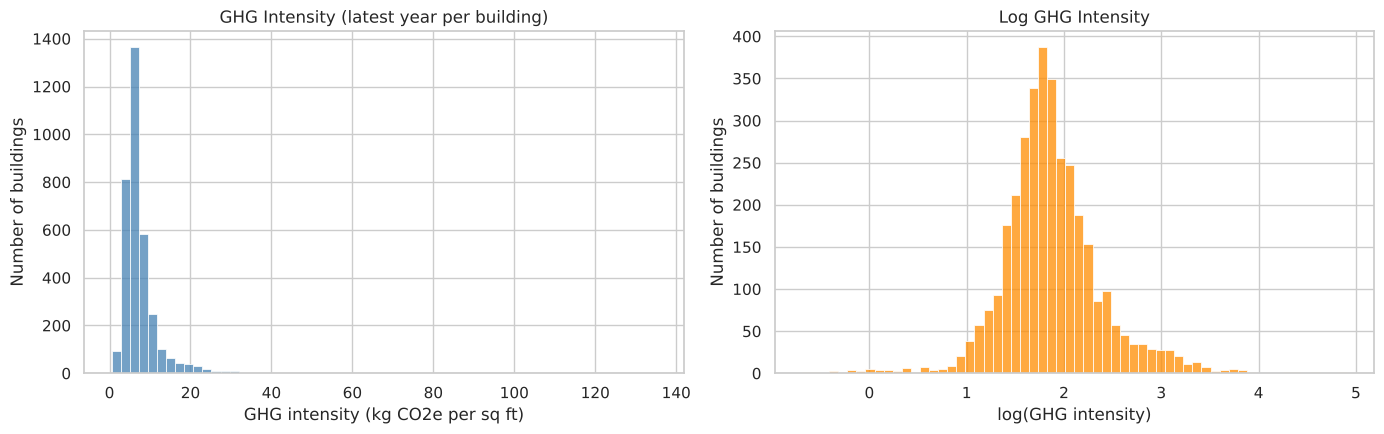

,count,mean,std,min,25%,50%,75%,max
ghg_intensity,3448.0,7.57,6.01,0.5,4.9,6.2,8.2,135.1


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(latest["ghg_intensity"], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("GHG Intensity (latest year per building)")
axes[0].set_xlabel("GHG intensity (kg CO2e per sq ft)")
axes[0].set_ylabel("Number of buildings")
sns.histplot(latest["log_ghg_intensity"], bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("Log GHG Intensity")
axes[1].set_xlabel("log(GHG intensity)")
axes[1].set_ylabel("Number of buildings")
plt.tight_layout()
plt.show()
latest["ghg_intensity"].describe().round(2).to_frame().T

**Interpretation.** GHG intensity is strongly right-skewed: the median building emits 6.2 kg CO2e per sq ft a year and the middle half lies between 4.9 and 8.2, but a long tail reaches 135. On a log scale the distribution is close to symmetric, so the models in Part 2 predict log GHG intensity.

## 5.2 GHG intensity by property type

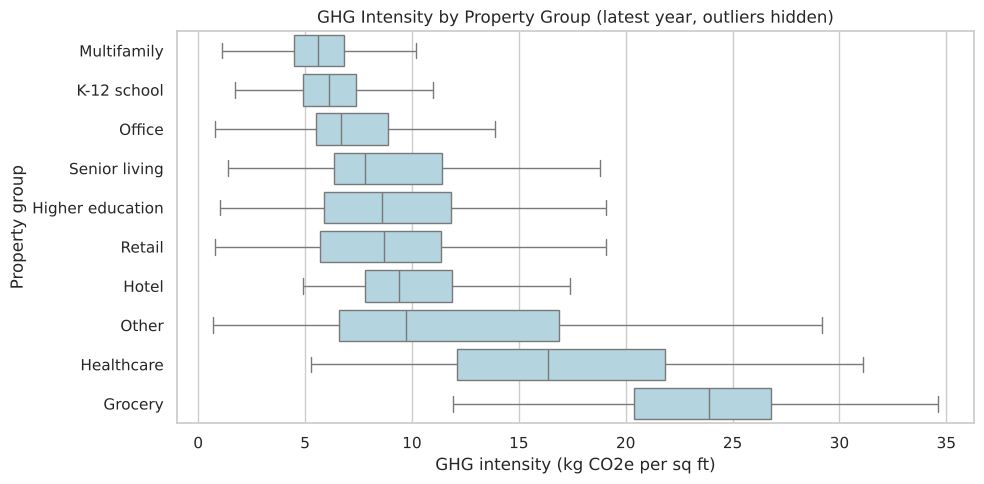

,buildings,median_ghg,median_eui,total_ghg_kt
property_group,,,,
Multifamily,1741,5.6,68.3,1997.5
K-12 school,536,6.1,72.4,412.2
Office,415,6.7,64.1,1349.2
Senior living,88,7.8,93.5,72.2
Higher education,112,8.6,87.8,252.7
Retail,124,8.7,80.4,162.1
Hotel,102,9.4,100.8,301.3
Other,225,9.7,102.0,895.3
Healthcare,56,16.4,190.2,651.9


In [9]:
order = latest.groupby("property_group")["ghg_intensity"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=latest, y="property_group", x="ghg_intensity", order=order, color="lightblue",
            showfliers=False, ax=ax)
ax.set_title("GHG Intensity by Property Group (latest year, outliers hidden)")
ax.set_xlabel("GHG intensity (kg CO2e per sq ft)")
ax.set_ylabel("Property group")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_ghg_by_type.png", dpi=150)
plt.show()

latest.groupby("property_group").agg(buildings=("ID", "size"),
                                     median_ghg=("ghg_intensity", "median"),
                                     median_eui=("site_eui", "median"),
                                     total_ghg_kt=("ghg_total", lambda s: s.sum() / 1000)
                                     ).round(1).sort_values("median_ghg")

**Interpretation.** Property type is the clearest divider. Grocery stores (median 23.9 kg CO2e/sq ft) and healthcare buildings (16.4) emit three to four times as much per sq ft as multifamily housing (5.6), K-12 schools (6.1) and offices (6.7), because refrigeration, ventilation and round-the-clock operation use far more energy (median site EUI 231.6 and 190.2 kBtu/sq ft against 64–72). In total emissions, however, multifamily buildings (about 2.0 million tonnes CO2e) and offices (1.3 million) dominate because there are so many of them.

## 5.3 Building age, size and location

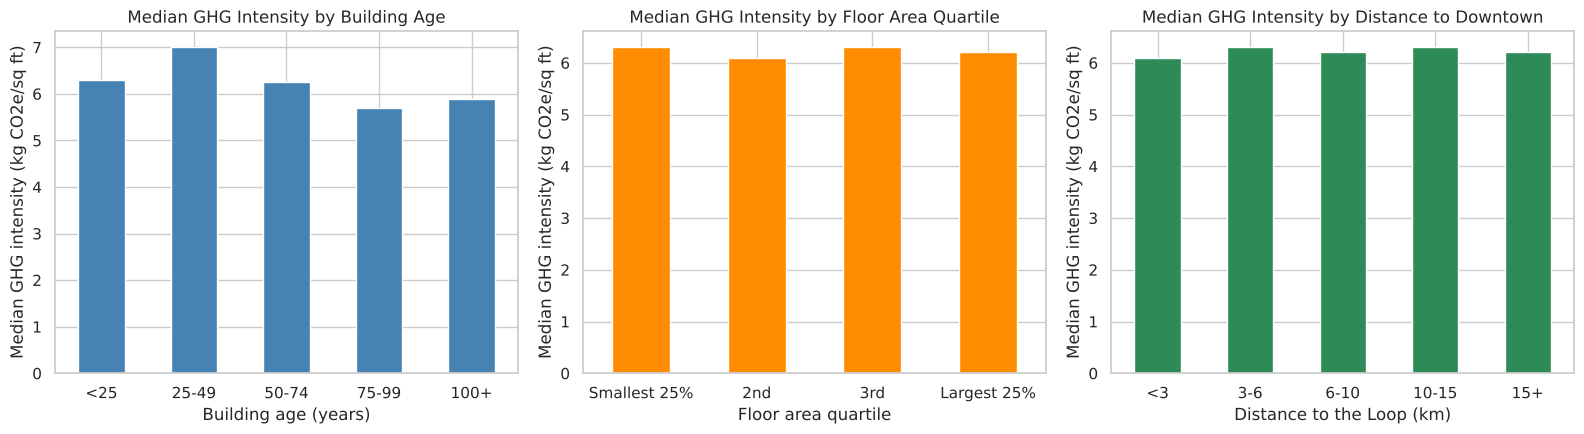

ghg_intensity       1.000
building_age       -0.098
log_floor_area      0.015
dist_downtown_km    0.007
n_buildings        -0.025
Name: ghg_intensity, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
age_bins = pd.cut(latest["building_age"], [0, 25, 50, 75, 100, 200], right=False,
                  labels=["<25", "25-49", "50-74", "75-99", "100+"])
latest.groupby(age_bins, observed=True)["ghg_intensity"].median().plot(kind="bar", ax=axes[0],
                                                                      color="steelblue")
axes[0].set_title("Median GHG Intensity by Building Age")
axes[0].set_xlabel("Building age (years)")
axes[0].set_ylabel("Median GHG intensity (kg CO2e/sq ft)")
axes[0].tick_params(axis="x", rotation=0)

size_bins = pd.qcut(latest["floor_area"], 4, labels=["Smallest 25%", "2nd", "3rd", "Largest 25%"])
latest.groupby(size_bins, observed=True)["ghg_intensity"].median().plot(kind="bar", ax=axes[1],
                                                                       color="darkorange")
axes[1].set_title("Median GHG Intensity by Floor Area Quartile")
axes[1].set_xlabel("Floor area quartile")
axes[1].set_ylabel("Median GHG intensity (kg CO2e/sq ft)")
axes[1].tick_params(axis="x", rotation=0)

dist_bins = pd.cut(latest["dist_downtown_km"], [0, 3, 6, 10, 15, 40], right=False,
                   labels=["<3", "3-6", "6-10", "10-15", "15+"])
latest.groupby(dist_bins, observed=True)["ghg_intensity"].median().plot(kind="bar", ax=axes[2],
                                                                       color="seagreen")
axes[2].set_title("Median GHG Intensity by Distance to Downtown")
axes[2].set_xlabel("Distance to the Loop (km)")
axes[2].set_ylabel("Median GHG intensity (kg CO2e/sq ft)")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(latest[["ghg_intensity", "building_age", "log_floor_area", "dist_downtown_km", "n_buildings"]]
      .corr(method="spearman")["ghg_intensity"].round(3))

**Interpretation.** Unlike property type, age, size and location show almost no relationship with GHG intensity on their own: median intensity stays between 5.7 and 7.0 kg CO2e/sq ft across age groups, between 6.1 and 6.3 across size quartiles, and between 6.1 and 6.3 at every distance from downtown. The Spearman correlations are all close to zero (age −0.10, others below 0.03). Any effect of these characteristics will have to come from combinations with property type, which Part 2 tests.

## 5.4 Energy mix by property type

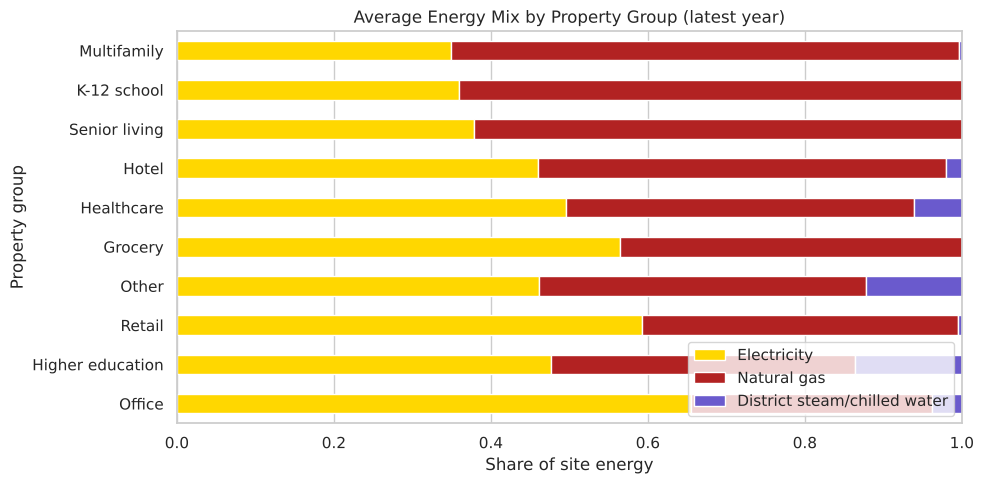

,elec_share,gas_share,district_share
property_group,,,
Office,0.655,0.306,0.039
Higher education,0.477,0.387,0.137
Retail,0.592,0.403,0.005
Other,0.462,0.416,0.123
Grocery,0.564,0.436,0.000
Healthcare,0.495,0.444,0.061
Hotel,0.460,0.520,0.021
Senior living,0.379,0.621,0.000
K-12 school,0.359,0.641,0.000


In [11]:
mix = (latest[latest["has_energy_mix"]].groupby("property_group")[["elec_share", "gas_share",
                                                                     "district_share"]]
       .mean().sort_values("gas_share"))
ax = mix.plot(kind="barh", stacked=True, figsize=(10, 5), color=["gold", "firebrick", "slateblue"])
ax.set_title("Average Energy Mix by Property Group (latest year)")
ax.set_xlabel("Share of site energy")
ax.set_ylabel("Property group")
ax.legend(["Electricity", "Natural gas", "District steam/chilled water"], loc="lower right")
plt.tight_layout()
plt.show()
mix.round(3)

**Interpretation.** Residential and school buildings get almost two-thirds of their energy from natural gas (multifamily 64.6%, K-12 64.1%, senior living 62.1%), mostly for space and water heating, whereas offices run mainly on electricity (65.5%). District steam and chilled water matter only for higher education (13.7%) and the 'Other' group (12.3%); just 4.1% of buildings use any district energy. Gas-heated buildings are the obvious candidates for electrification with heat pumps.

## 5.5 Are buildings getting cleaner? GHG intensity 2018–2023

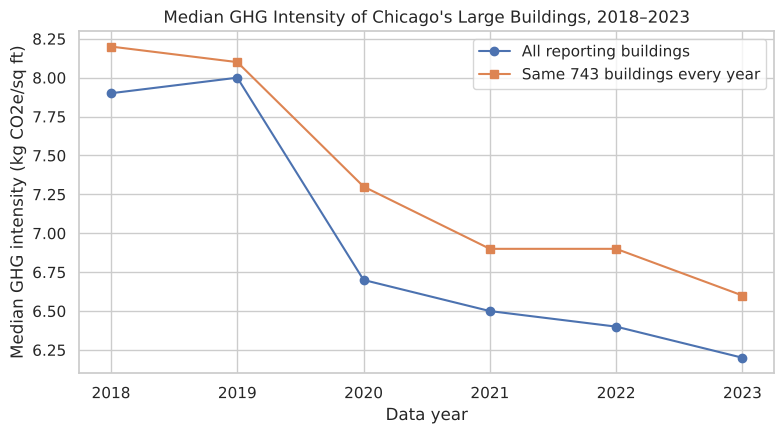

Balanced panel change 2018-2023: -19.5%


,median_all,reports,median_balanced_panel
year,,,
2018,7.9,2751,8.2
2019,8.0,1185,8.1
2020,6.7,2883,7.3
2021,6.5,2549,6.9
2022,6.4,2539,6.9
2023,6.2,2572,6.6


In [12]:
trend = df[df["year"].between(2018, 2023)]
all_bldg = trend.groupby("year")["ghg_intensity"].agg(["median", "size"])

# Balanced panel: only buildings that reported in every year 2018-2023, so the trend is not driven by
# which buildings happened to report (2019 has far fewer reports)
years_per_bldg = trend.groupby("ID")["year"].nunique()
panel_ids = years_per_bldg[years_per_bldg == 6].index
panel = trend[trend["ID"].isin(panel_ids)].groupby("year")["ghg_intensity"].median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(all_bldg.index, all_bldg["median"], marker="o", label="All reporting buildings")
ax.plot(panel.index, panel.values, marker="s", label=f"Same {len(panel_ids):,} buildings every year")
ax.set_title("Median GHG Intensity of Chicago's Large Buildings, 2018–2023")
ax.set_xlabel("Data year")
ax.set_ylabel("Median GHG intensity (kg CO2e/sq ft)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_trend.png", dpi=150)
plt.show()

out = all_bldg.rename(columns={"median": "median_all", "size": "reports"})
out["median_balanced_panel"] = panel
print(f"Balanced panel change 2018-2023: {(panel[2023] / panel[2018] - 1):.1%}")
out.round(2)

**Interpretation.** Median GHG intensity fell from 7.9 kg CO2e/sq ft in 2018 to 6.2 in 2023 across all reporting buildings. Because the set of reporting buildings changes from year to year (2019 has only 1,185 reports), the balanced panel of the 743 buildings that reported every year is the fairer comparison: their median fell from 8.2 to 6.6, a **19.5% drop**. Part of this decline likely reflects a cleaner electricity grid (the emission factor used to convert electricity to CO2e has fallen) and the 2020 pandemic, not only building upgrades; the dataset cannot separate these causes.

In [13]:
# Save the cleaned data for Parts 2 and 3
os.makedirs("../data/processed", exist_ok=True)
keep = ["ID", "year", "property_type", "property_group", "floor_area", "log_floor_area", "year_built",
        "building_age", "n_buildings", "community_area", "lat", "lon", "dist_downtown_km",
        "site_eui", "log_site_eui", "ghg_intensity", "log_ghg_intensity", "ghg_total", "energy_star",
        "elec_share", "gas_share", "district_share", "has_energy_mix"]
df[keep].to_csv("../data/processed/building_years_clean_python.csv", index=False)
latest[keep].to_csv("../data/processed/buildings_latest_python.csv", index=False)
print("Saved", df[keep].shape, latest[keep].shape)

Saved (21618, 23) (3448, 23)


---
# 6. Summary and the two project questions


The cleaned data hold 21,618 building-years and 3,448 buildings (latest year each), with no missing values in the modelling columns. GHG intensity is skewed, differs strongly by property type, barely varies with age, size or location on their own, and has fallen by about a fifth since 2018. Ten percent of buildings produce 50.8% of the total emissions, which is why understanding the high emitters matters. The project addresses two questions:

1. **Which building characteristics best predict a building's GHG intensity?** Regression (linear
   regression, regression tree, random forest) using only characteristics known without the energy
   bills: property type, floor area, age, number of buildings, distance to downtown and data year.
2. **What distinct energy-use profiles exist among Chicago's large buildings?** k-means clustering on
   energy intensity, energy mix and GHG intensity, with the clusters profiled by property type, age and
   size.